# N-Step Replay Buffer — Stable Baselines 3
Source: `stable_baselines3/common/buffers.py`

In [19]:
import warnings
from abc import ABC, abstractmethod
from typing import Any

import numpy as np
import torch as th
from gymnasium import spaces

In [20]:
from dataclasses import dataclass
from stable_baselines3.common.buffers import ReplayBufferSamples, NStepReplayBuffer

In [21]:
from stable_baselines3.common.type_aliases import ReplayBufferSamples


class PrioritizedReplayBufferSamples(ReplayBufferSamples):
    """
    Extends ReplayBufferSamples (NamedTuple) with PER-specific fields.

    NamedTuple itself has __slots__ = () — no __dict__.
    A subclass without __slots__ gets __dict__ automatically, so we can
    set extra attributes freely in __new__.
    (Nonempty __slots__ on a NamedTuple subtype is explicitly forbidden.)
    """

    def __new__(cls, *args, weights=None, indices=None, **kwargs):
        instance = super().__new__(cls, *args, **kwargs)
        instance.weights = weights   # IS correction weights, shape (B, 1)
        instance.indices = indices   # buffer indices, numpy — for _update_priorities
        return instance

In [22]:
class SumTree:
    """
    Binary tree where each leaf stores a priority p_i and each internal node
    stores the sum of its children.  Root = total priority.

    Capacity is rounded up to the next power of 2 to guarantee a complete
    binary tree — required for the vectorized traversal in get().

    Layout (capacity=4):
        index:  0          ← root (sum of all)
               1    2
              3  4  5  6   ← leaves (buffer indices 0..3)

    Leaf for buffer index i lives at tree position i + capacity - 1.
    """

    def __init__(self, capacity: int):
        # Next power of 2 → complete binary tree, no out-of-bounds in traversal
        self.capacity = 1 << int(np.ceil(np.log2(max(capacity, 2))))
        self.tree = np.zeros(2 * self.capacity - 1, dtype=np.float64)

    def update(self, idx: int, priority: float) -> None:
        """Update leaf at buffer index idx and propagate delta to root."""
        tree_idx = idx + self.capacity - 1
        delta = priority - self.tree[tree_idx]
        self.tree[tree_idx] = priority
        while tree_idx != 0:
            tree_idx = (tree_idx - 1) // 2
            self.tree[tree_idx] += delta

    def get(self, values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """
        Vectorized traversal: for each value in [0, total], walk the tree
        left if value <= left-child sum, else subtract left sum and go right.
        Returns (buffer_indices, priorities) both shape (B,).
        """
        idx   = np.zeros(len(values), dtype=np.int64)
        depth = int(np.log2(self.capacity))   # exact depth for power-of-2 capacity
        for _ in range(depth):
            left     = 2 * idx + 1
            go_right = values > self.tree[left]
            values  -= self.tree[left] * go_right
            idx      = np.where(go_right, left + 1, left)
        data_idx = idx - (self.capacity - 1)
        return data_idx, self.tree[idx]

    @property
    def total(self) -> float:
        return float(self.tree[0])

In [ ]:
from replay_buffer import PrioritizedReplayBuffer, PrioritizedReplayBufferSamples

# PER_DQN — inherits SB3's DQN, swaps buffer and overrides train()

In [24]:
from stable_baselines3 import DQN
from torch.nn import functional as F

In [25]:
class PER_DQN(DQN):
    def __init__(
        self,
        *args,
        alpha: float = 0.5,
        beta: float = 0.4,
        total_samples: int = 1_000_000,
        epsilon_per: float = 0.01,
        n_steps: int = 3,
        **kwargs,
    ):
        # Let DQN.__init__ run fully — creates self.replay_buffer via _setup_model()
        super().__init__(*args, n_steps=n_steps, **kwargs)

        # Replace uniform NStepReplayBuffer with PrioritizedReplayBuffer
        self.replay_buffer = PrioritizedReplayBuffer(
            self.buffer_size,
            self.observation_space,
            self.action_space,
            device=self.device,
            n_envs=self.n_envs,
            n_steps=n_steps,
            gamma=self.gamma,
            alpha=alpha,
            beta=beta,
            total_samples=total_samples,
            epsilon=epsilon_per,
        )

    def train(self, gradient_steps: int, batch_size: int = 100) -> None:
        self.policy.set_training_mode(True)
        self._update_learning_rate(self.policy.optimizer)

        losses = []
        for _ in range(gradient_steps):
            samples = self.replay_buffer.sample(batch_size, env=self._vec_normalize_env)

            with th.no_grad():
                next_q_values = self.q_net_target(samples.next_observations)
                next_q_values, _ = next_q_values.max(dim=1)
                next_q_values  = next_q_values.reshape(-1, 1)
                target_q = samples.rewards + (1 - samples.dones) * samples.discounts * next_q_values

            current_q = self.q_net(samples.observations)
            current_q_values = th.gather(current_q, dim=1, index=samples.actions.long())

            # IS-weighted Huber loss  (only diff vs DQN: weights + reduction='none')
            loss = (samples.weights * F.smooth_l1_loss(current_q_values, target_q, reduction="none")).mean()
            losses.append(loss.item())

            self.policy.optimizer.zero_grad()
            loss.backward()
            th.nn.utils.clip_grad_norm_(self.policy.parameters(), self.max_grad_norm)
            self.policy.optimizer.step()

            # Update priorities with n-step TD errors
            with th.no_grad():
                td_errors = target_q - current_q_values
            self.replay_buffer._update_priorities(samples.indices, td_errors.cpu().numpy())

        self._n_updates += gradient_steps
        self.logger.record("train/n_updates", self._n_updates, exclude="tensorboard")
        self.logger.record("train/loss", np.mean(losses))

# Comparison: DQN vs PER_DQN on CartPole-v1

In [28]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3.common.callbacks import BaseCallback


class RewardLoggerCallback(BaseCallback):
    """Records mean episode reward over a rolling window after each rollout."""
    def __init__(self, window: int = 20):
        super().__init__()
        self.window = window
        self.episode_rewards: list[float] = []
        self.timesteps: list[int] = []
        self._current_rewards: dict[int, float] = {}

    def _on_step(self) -> bool:
        for i, info in enumerate(self.locals["infos"]):
            if "episode" in info:
                self.episode_rewards.append(info["episode"]["r"])
                if len(self.episode_rewards) >= self.window:
                    self.timesteps.append(self.num_timesteps)
        return True


def run(model_cls, env_id: str = "CartPole-v1", total_timesteps: int = 50_000,
        seed: int = 0, **kwargs) -> RewardLoggerCallback:
    env = gym.make(env_id)
    cb  = RewardLoggerCallback(window=20)
    model = model_cls(
        "MlpPolicy", env, seed=seed, verbose=0,
        learning_starts=1_000,
        **kwargs,
    )
    model.learn(total_timesteps=total_timesteps, callback=cb)
    env.close()
    return cb


TOTAL = 50_000
SEEDS = [0, 1, 2, 3, 5, 8, 13, 21, 34, 55]

shared = dict(
    buffer_size     = 10_000,
    batch_size      = 64,
    learning_rate   = 1e-3,
    gamma           = 0.99,
    train_freq      = 4,
    gradient_steps  = 1,
    target_update_interval = 500,
)

results: dict[str, list[RewardLoggerCallback]] = {"DQN": [], "PER_DQN": []}

for seed in SEEDS:
    print(f"seed {seed}  DQN...", end=" ", flush=True)
    results["DQN"].append(run(DQN, seed=seed, total_timesteps=TOTAL, **shared))
    print("PER_DQN...", end=" ", flush=True)
    results["PER_DQN"].append(run(
        PER_DQN, seed=seed, total_timesteps=TOTAL,
        n_steps=3, alpha=0.5, beta=0.4,
        total_samples=TOTAL, epsilon_per=0.01,
        **shared,
    ))
    print("done")
print("All runs complete.")

seed 0  DQN... PER_DQN... done
seed 1  DQN... PER_DQN... done
seed 2  DQN... PER_DQN... done
seed 3  DQN... PER_DQN... done
seed 5  DQN... PER_DQN... done
seed 8  DQN... PER_DQN... done
seed 13  DQN... PER_DQN... done
seed 21  DQN... PER_DQN... done
seed 34  DQN... PER_DQN... done
seed 55  DQN... PER_DQN... done
All runs complete.


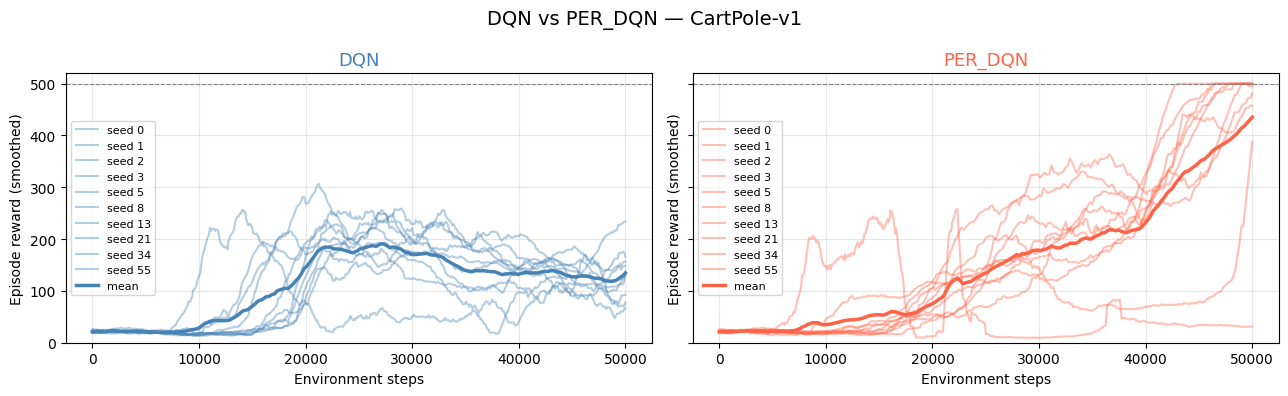

              final 5k mean    steps to 400
--------------------------------------------
       DQN           128.1         50,000
   PER_DQN           386.6         45,087


In [29]:
def smooth(x: list[float], w: int = 20) -> np.ndarray:
    return np.convolve(x, np.ones(w) / w, mode="valid")


fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
colors = {"DQN": "steelblue", "PER_DQN": "tomato"}

for ax, (name, runs) in zip(axes, results.items()):
    for i, cb in enumerate(runs):
        y = smooth(cb.episode_rewards)
        x = np.linspace(0, TOTAL, len(y))
        ax.plot(x, y, alpha=0.4, color=colors[name], label=f"seed {SEEDS[i]}")

    # mean across seeds (interpolate onto common x grid)
    x_common = np.linspace(0, TOTAL, 200)
    interp = [np.interp(x_common, np.linspace(0, TOTAL, len(smooth(cb.episode_rewards))),
                        smooth(cb.episode_rewards)) for cb in runs]
    mean_y = np.mean(interp, axis=0)
    ax.plot(x_common, mean_y, color=colors[name], linewidth=2.5, label="mean")

    ax.set_title(name, fontsize=13, color=colors[name])
    ax.set_xlabel("Environment steps")
    ax.set_ylabel("Episode reward (smoothed)")
    ax.legend(fontsize=8)
    ax.set_ylim(0, 520)
    ax.axhline(500, color="gray", linestyle="--", linewidth=0.8, label="max")
    ax.grid(alpha=0.3)

fig.suptitle("DQN vs PER_DQN — CartPole-v1", fontsize=14)
plt.tight_layout()
plt.show()

# Summary table
print(f"{'':>10}  {'final 5k mean':>15}  {'steps to 400':>14}")
print("-" * 44)
for name, runs in results.items():
    finals, steps_to = [], []
    for cb in runs:
        r = np.array(cb.episode_rewards)
        finals.append(r[-50:].mean() if len(r) >= 50 else r.mean())
        above = np.where(smooth(r) >= 400)[0]
        steps_to.append(int(above[0] / len(smooth(r)) * TOTAL) if len(above) else TOTAL)
    print(f"{name:>10}  {np.mean(finals):>14.1f}  {np.mean(steps_to):>13,.0f}")